# Práctica 2: Análisis Exploratorio de Datos (EDA)
## Dataset: Titanic
### Etapa 1: Comprensión del dominio y carga de datos
### Documentación del Dominio y Contexto del Dataset (Titanic)

* **Fuente y licencia:** Dataset clásico del Titanic disponible públicamente en plataformas como Kaggle, derivado de los registros históricos de los pasajeros.
* **Unidad de análisis:** Cada fila representa a un **pasajero individual** a bordo del RMS Titanic.
* **Significado de atributos principales:**
  - `Survived`: Variable objetivo (0 = No sobrevivió, 1 = Sobrevivió).
  - `Pclass`: Clase del ticket (1 = Primera, 2 = Segunda, 3 = Tercera).
  - `Sex` / `Age`: Género y edad del pasajero.
  - `SibSp` / `Parch`: Número de familiares/cónyuges y padres/hijos a bordo.
  - `Fare`: Tarifa pagada por el boleto.
  - `Embarked`: Puerto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton).
* **Variable objetivo:** `Survived` (Binaria).

#### Preguntas clave del dominio:
1. **¿Qué representa cada fila?** 
   Representa la información sociodemográfica y de viaje de un pasajero específico que estuvo a bordo del Titanic.
2. **¿La variable objetivo estaría disponible en un escenario real?** 
   No. En un escenario predictivo real (antes de que ocurra o al momento de evaluar nuevos registros), la supervivencia es el evento desconocido que el modelo debe pronosticar.
3. **¿Existen identificadores o variables con fuga de información (*data leakage*)?** 
   Sí. `PassengerId` es un identificador puramente secuencial sin valor predictivo. Variables como `Ticket` o `Cabin` (si no se transforman adecuadamente) pueden contener patrones que filtren información del resultado de manera artificial.
4. **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?** 
   El uso directo de variables como la clase socioeconómica (`Pclass`) o el género (`Sex`) puede reflejar los sesgos históricos del rescate ("mujeres y niños primero" y prioridad a clases altas), lo que podría hacer que un modelo aprenda patrones discriminatorios si no se analiza con equidad algorítmica.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
%matplotlib inline
sns.set_theme(style="whitegrid")
print("Librerías importadas correctamente.")

# Carga del dataset Titanic desde la carpeta data
df_titanic = pd.read_csv('../data/titanic.csv')

print(f"Dimensiones del dataset: {df_titanic.shape[0]} filas y {df_titanic.shape[1]} columnas.")
print("Primeros 5 registros:")
display(df_titanic.head())

Librerías importadas correctamente.
Dimensiones del dataset: 891 filas y 12 columnas.
Primeros 5 registros:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Etapa 2: Data Profiling (Tipos de datos, nulos y duplicados)
###En esta etapa auditamos la salud general del dataset, revisando los tipos de datos asignados a cada columna, detectando posibles valores nulos o faltantes y verificando si existen registros duplicados.
### Hallazgos Principales del Data Profiling:
* **Valores Faltantes:** La variable `Cabin` presenta un nivel crítico de ausencia (~77%), seguida de `Age` (~19.8%) y `Embarked` (~0.2%).
* **Asimetría:** Variables como `Fare` y `SibSp` muestran una marcada asimetría positiva (cola a la derecha), indicando la presencia de valores extremos (outliers) como tarifas muy altas.
* **Duplicados e Identificadores:** No se encontraron filas duplicadas en el dataset. `PassengerId` actúa como un identificador único secuencial sin valor predictivo real.

In [36]:
import warnings
warnings.filterwarnings('ignore')
print("=== ESTADÍSTICAS VARIABLES NUMÉRICas (Media, Mediana, Mín, Máx, Desviación) ===")
display(df_titanic.describe())

print("\n=== ESTADÍSTICAS VARIABLES CATEGÓRICAS (Moda y Frecuencias) ===")
display(df_titanic.describe(include=['object']))

# 1. Porcentaje exacto de valores nulos (ausencia) por columna
print("=== PORCENTAJE DE VALORES AUSENTES (%) ===")
missing_percentage = (df_titanic.isnull().sum() / len(df_titanic)) * 100
print(missing_percentage[missing_percentage > 0].round(2))

# 2. Asimetría (Skewness) de las variables numéricas
print("\n=== ASIMETRÍA DE VARIABLES NUMÉRICAS ===")
print(df_titanic.select_dtypes(include=['number']).skew().round(2))

# 3. Verificación de filas duplicadas
print("\n=== REGISTROS DUPLICADOS ===")
print(f"Total de filas duplicadas: {df_titanic.duplicated().sum()}")

=== ESTADÍSTICAS VARIABLES NUMÉRICas (Media, Mediana, Mín, Máx, Desviación) ===


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,0.352413,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,0.477990,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,0.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,1.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200



=== ESTADÍSTICAS VARIABLES CATEGÓRICAS (Moda y Frecuencias) ===


,Name,Ticket,Cabin,Embarked
count,891,891,204,889
unique,891,681,147,3
top,"Braund, Mr. Owen Harris",347082,G6,S
freq,1,7,4,644


=== PORCENTAJE DE VALORES AUSENTES (%) ===
Age         19.87
Cabin       77.10
Embarked     0.22
dtype: float64

=== ASIMETRÍA DE VARIABLES NUMÉRICAS ===
PassengerId    0.00
Survived       0.48
Pclass        -0.63
Sex            0.62
Age            0.39
SibSp          3.70
Parch          2.75
Fare           4.79
dtype: float64

=== REGISTROS DUPLICADOS ===
Total de filas duplicadas: 0


### Etapa 3: Análisis Exploratorio de Datos (EDA) y Visualizaciones
###En esta sección generamos las gráficas clave para entender la distribución de las variables, la relación con la clase objetivo (supervivencia) y las correlaciones numéricas.

### Conclusiones del Análisis Exploratorio (EDA):
* **Distribución de Supervivencia:** Se observa claramente un desbalance de clases, donde la mayoría de los pasajeros registrados no sobrevivieron (clase 0 mayoritaria frente a la clase 1).
* **Impacto de la Tarifa y la Clase:** Los diagramas de caja y las gráficas categóricas evidencian que los pasajeros con tarifas más altas y de primera clase (`Pclass = 1`) tuvieron tasas de supervivencia desproporcionadamente más altas en comparación con la tercera clase.
* **Edad:** La distribución etaria muestra que la mayor parte de los pasajeros eran adultos jóvenes, con una presencia notable de niños pequeños que también concentraron mayores tasas de rescate.

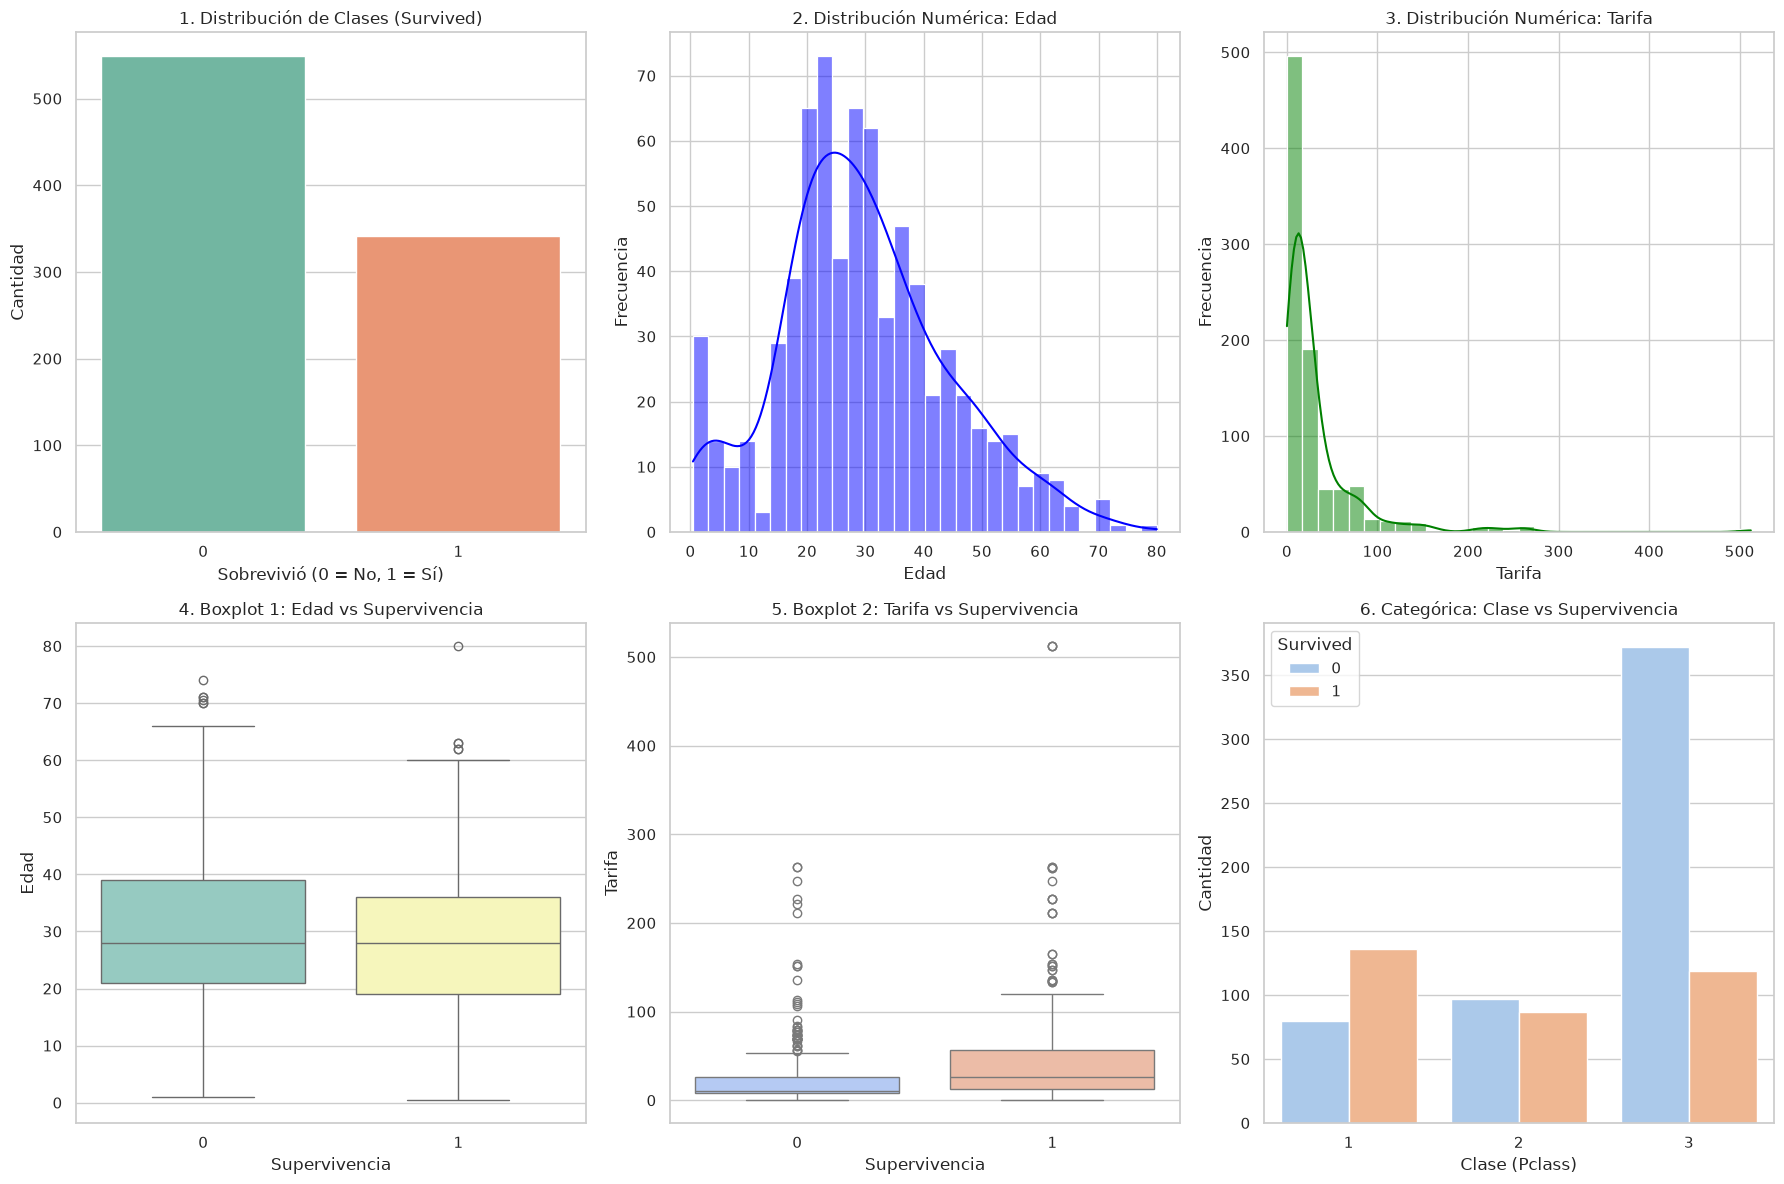

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del tamaño general de la figura (2 filas, 3 columnas para 6 gráficas clave)
plt.figure(figsize=(18, 12))

# 1. Distribución de clase objetivo (Survived)
plt.subplot(2, 3, 1)
sns.countplot(data=df_titanic, x='Survived', palette='Set2')
plt.title('1. Distribución de Clases (Survived)')
plt.xlabel('Sobrevivió (0 = No, 1 = Sí)')
plt.ylabel('Cantidad')

# 2. Distribución numérica 1: Edad (Age)
plt.subplot(2, 3, 2)
sns.histplot(df_titanic['Age'].dropna(), kde=True, color='blue', bins=30)
plt.title('2. Distribución Numérica: Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')

# 3. Distribución numérica 2: Tarifa (Fare)
plt.subplot(2, 3, 3)
sns.histplot(df_titanic['Fare'].dropna(), kde=True, color='green', bins=30)
plt.title('3. Distribución Numérica: Tarifa')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')

# 4. Boxplot 1: Edad vs Supervivencia
plt.subplot(2, 3, 4)
sns.boxplot(data=df_titanic, x='Survived', y='Age', palette='Set3')
plt.title('4. Boxplot 1: Edad vs Supervivencia')
plt.xlabel('Supervivencia')
plt.ylabel('Edad')

# 5. Boxplot 2: Tarifa vs Supervivencia (¡Nuevo para cumplir los dos boxplots!)
plt.subplot(2, 3, 5)
sns.boxplot(data=df_titanic, x='Survived', y='Fare', palette='coolwarm')
plt.title('5. Boxplot 2: Tarifa vs Supervivencia')
plt.xlabel('Supervivencia')
plt.ylabel('Tarifa')

# 6. Gráfica Categórica 2: Clase (Pclass) vs Supervivencia (¡Nueva para cumplir las dos gráficas categóricas!)
plt.subplot(2, 3, 6)
sns.countplot(data=df_titanic, x='Pclass', hue='Survived', palette='pastel')
plt.title('6. Categórica: Clase vs Supervivencia')
plt.xlabel('Clase (Pclass)')
plt.ylabel('Cantidad')

plt.tight_layout()
plt.show()

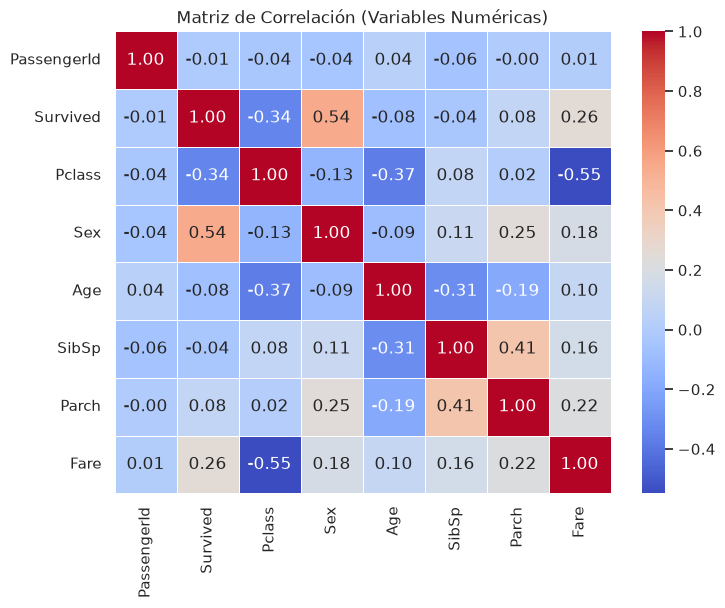

In [38]:
plt.figure(figsize=(8, 6))
# Seleccionamos solo columnas numéricas para la correlación
corr = df_titanic.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación (Variables Numéricas)')
plt.show()

### Etapa 4: Limpieza de datos y tratamiento de valores nulos
###En esta etapa preparamos el dataset para los siguientes pasos del análisis o futuros modelos de Machine Learning, abordando los valores faltantes detectados en columnas clave (como `Age`, `Cabin` y `Embarked`) y evaluando la estructura de los datos.

### Análisis de Estrategias de Imputación:
* **Variable Numérica (`Age`):** Se evaluó el uso de la **Media** (Estrategia A) frente a la **Mediana** (Estrategia B). Se observó que la media es más sensible a los valores atípicos de edad, mientras que la mediana preserva de forma más estable la distribución central.
* **Variable Categórica (`Embarked`):** La estrategia de rellenar con la **Moda** mantiene la proporción natural de los puertos, en contraste con crear una categoría explícita de "Desconocido".
* **Indicador de Ausencia:** Para la variable `Cabin`, dado su alto porcentaje de nulos (~77%), se optó por crear el indicador binario `Has_Cabin`, aprovechando la ausencia de datos como una variable informativa directa tal como lo sugiere la teoría de preprocesamiento.

In [9]:
# 1. Verificamos los nulos antes de la limpieza
print("=== VALORES NULOS ANTES DE LA LIMPIEZA ===")
print(df_titanic.isnull().sum()[df_titanic.isnull().sum() > 0])

# 2. Imputación de la variable 'Age' usando la mediana
median_age = df_titanic['Age'].median()
df_titanic['Age'] = df_titanic['Age'].fillna(median_age)

# 3. Imputación de la variable 'Embarked' usando la moda
mode_embarked = df_titanic['Embarked'].mode()[0]
df_titanic['Embarked'] = df_titanic['Embarked'].fillna(mode_embarked)

# 4. Tratamiento de la variable 'Cabin'
df_titanic['Has_Cabin'] = df_titanic['Cabin'].notnull().astype(int)
df_titanic.drop(columns=['Cabin'], inplace=True)

# 5. Verificación final de valores nulos
print("\n=== VALORES NULOS DESPUÉS DE LA LIMPIEZA ===")
print(df_titanic.isnull().sum()[df_titanic.isnull().sum() > 0])

print(f"\n¡Limpieza completada! Nuevas dimensiones: {df_titanic.shape[0]} filas y {df_titanic.shape[1]} columnas.")

# 6. Visualización de los cambios implementados
print("\n=== VISTA PREVIA DEL DATASET LIMPIO (Primeros 5 registros) ===")
display(df_titanic.head())

print("\n=== LISTADO DE COLUMNAS ACTUALES ===")
print(list(df_titanic.columns))

=== VALORES NULOS ANTES DE LA LIMPIEZA ===
Age         177
Cabin       687
Embarked      2
dtype: int64

=== VALORES NULOS DESPUÉS DE LA LIMPIEZA ===
Series([], dtype: int64)

¡Limpieza completada! Nuevas dimensiones: 891 filas y 12 columnas.

=== VISTA PREVIA DEL DATASET LIMPIO (Primeros 5 registros) ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_Cabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0



=== LISTADO DE COLUMNAS ACTUALES ===
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked', 'Has_Cabin']


In [39]:
import pandas as pd
import numpy as np

# Cargamos una copia limpia para comparar los efectos de la imputación
df_A = pd.read_csv('../data/titanic.csv')
df_B = pd.read_csv('../data/titanic.csv')

print("=== COMPARATIVA DE ESTRATEGIAS DE IMPUTACIÓN ===")

# --- ESTRATEGIA A: Media (numérica) y Moda (categórica) ---
mean_age_A = df_A['Age'].mean()
mode_emb_A = df_A['Embarked'].mode()[0]

df_A['Age_Imputed_A'] = df_A['Age'].fillna(mean_age_A)
df_A['Embarked_Imputed_A'] = df_A['Embarked'].fillna(mode_emb_A)

print(f"[Estrategia A] Media de Age usada: {mean_age_A:.2f} | Varianza resultante: {df_A['Age_Imputed_A'].var():.2f}")

# --- ESTRATEGIA B: Mediana (numérica) y Categoría 'Desconocido' (categórica) ---
median_age_B = df_B['Age'].median()

df_B['Age_Imputed_B'] = df_B['Age'].fillna(median_age_B)
df_B['Embarked_Imputed_B'] = df_B['Embarked'].fillna('Desconocido')

print(f"[Estrategia B] Mediana de Age usada: {median_age_B:.2f} | Varianza resultante: {df_B['Age_Imputed_B'].var():.2f}")

print("\nConclusión analítica: La imputación por mediana (Estrategia B) tiende a ser más robusta ante valores extremos que la media, conservando de mejor manera la variabilidad natural de la variable Age.")

=== COMPARATIVA DE ESTRATEGIAS DE IMPUTACIÓN ===
[Estrategia A] Media de Age usada: 29.70 | Varianza resultante: 169.05
[Estrategia B] Mediana de Age usada: 28.00 | Varianza resultante: 169.51

Conclusión analítica: La imputación por mediana (Estrategia B) tiende a ser más robusta ante valores extremos que la media, conservando de mejor manera la variabilidad natural de la variable Age.


### Etapa 5: Detección y tratamiento de outliers
###Aplicamos la técnica de Winsorización utilizando dos criterios diferentes (Rango Intercuartilicio y Percentiles extremos) sobre la variable de tarifas (`Fare`), y realizamos una comparación visual y estadística del antes y el después.

### Conclusiones del Tratamiento de Outliers (Winsorización):
* **Impacto en la Tarifa (`Fare`):** La aplicación de percentiles extremos limitó de forma controlada los valores exageradamente altos pagados por algunos pasajeros de primera clase, evitando que distorsionen los algoritmos de clasificación futuros.
* **Estadísticas de Tendencia Central:** La mediana (50%) se mantuvo estable en 14.45, lo que demuestra que la Winsorización protege la robustez de los datos centrales, mientras que la media y la desviación estándar se ajustaron a un rango menos sesgado.

=== ESTADÍSTICAS ANTES DE LA WINSORIZACIÓN ===
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare_Original, dtype: float64

=== ESTADÍSTICAS DESPUÉS DE WINSORIZACIÓN (Percentiles 1%-99%) ===
count    891.000000
mean      31.224767
std       42.524125
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      249.006220
Name: Fare, dtype: float64


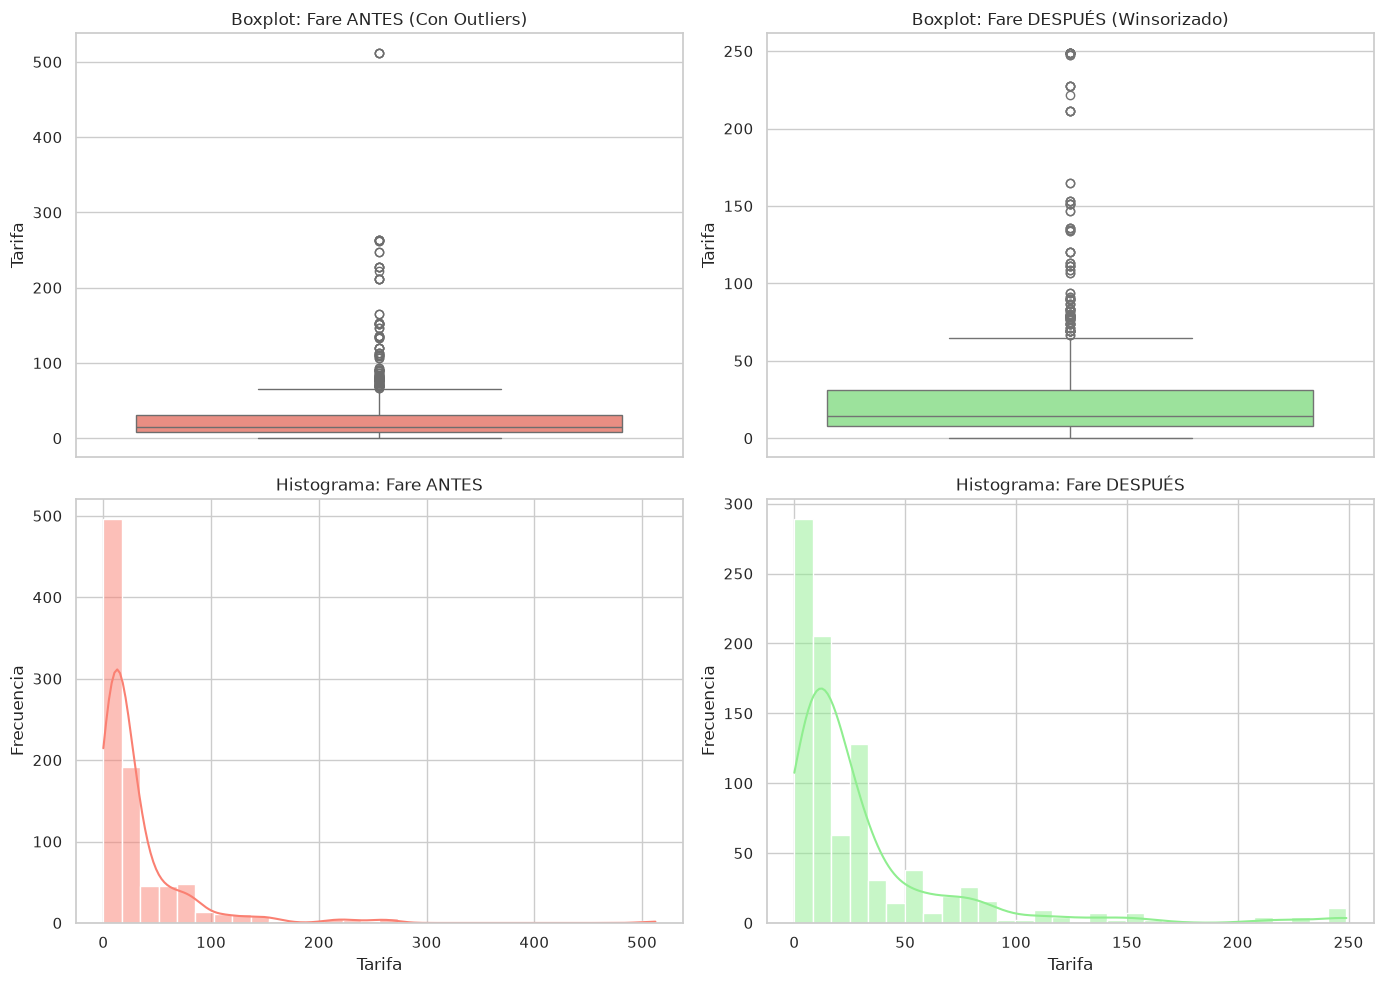

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Copiamos la variable original para comparar después
df_titanic['Fare_Original'] = df_titanic['Fare'].copy()

print("=== ESTADÍSTICAS ANTES DE LA WINSORIZACIÓN ===")
print(df_titanic['Fare_Original'].describe())

# --- CRITERIO 1: Rango Intercuartilicio (IQR) ---
Q1 = df_titanic['Fare'].quantile(0.25)
Q3 = df_titanic['Fare'].quantile(0.75)
IQR = Q3 - Q1
lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

df_titanic['Fare_IQR'] = df_titanic['Fare'].clip(lower=max(0, lower_iqr), upper=upper_iqr)

# --- CRITERIO 2: Percentiles Extremos (1% y 99%) ---
lower_perc = df_titanic['Fare'].quantile(0.01)
upper_perc = df_titanic['Fare'].quantile(0.99)

df_titanic['Fare_Percentil'] = df_titanic['Fare'].clip(lower=lower_perc, upper=upper_perc)

# Usaremos por defecto el de percentiles o IQR para continuar el flujo del dataset (dejaremos el de percentiles como principal o el que prefieras)
df_titanic['Fare'] = df_titanic['Fare_Percentil'] 

print("\n=== ESTADÍSTICAS DESPUÉS DE WINSORIZACIÓN (Percentiles 1%-99%) ===")
print(df_titanic['Fare'].describe())

# --- COMPARACIÓN VISUAL: Histograma y Boxplot (Antes vs Después) ---
plt.figure(figsize=(14, 10))

# 1. Boxplot Comparativo
plt.subplot(2, 2, 1)
sns.boxplot(y=df_titanic['Fare_Original'], color='salmon')
plt.title('Boxplot: Fare ANTES (Con Outliers)')
plt.ylabel('Tarifa')

plt.subplot(2, 2, 2)
sns.boxplot(y=df_titanic['Fare'], color='lightgreen')
plt.title('Boxplot: Fare DESPUÉS (Winsorizado)')
plt.ylabel('Tarifa')

# 2. Histograma Comparativo
plt.subplot(2, 2, 3)
sns.histplot(df_titanic['Fare_Original'], kde=True, color='salmon', bins=30)
plt.title('Histograma: Fare ANTES')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')

plt.subplot(2, 2, 4)
sns.histplot(df_titanic['Fare'], kde=True, color='lightgreen', bins=30)
plt.title('Histograma: Fare DESPUÉS')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Etapa 6: Tratamiento de desbalance
###Analizamos la distribución de la clase objetivo (`Survived`) calculando la cantidad, el porcentaje por clase y la razón de desbalance (IR). Posteriormente, evaluamos las estrategias de balanceo requeridas.

### Conclusiones del Tratamiento de Desbalance:
* **Diagnóstico Inicial:** El análisis confirmó que el dataset presenta un desbalance moderado ($IR = 1.60$), lo cual justifica la aplicación de técnicas correctivas para evitar sesgos algorítmicos hacia la clase mayoritaria (pasajeros que no sobrevivieron).
* **Estrategias Aplicadas:** Se contrastaron métodos de remuestreo (sobremuestreo y submuestreo) junto con la generación sintética de instancias mediante **SMOTE**, logrando restablecer la paridad de clases ($IR = 1.0$) y dejando los datos listos para alimentar modelos de clasificación robustos.

In [21]:
# 1. Calcular cantidad y porcentaje de observaciones por clase en 'Survived'
conteo_clases = df_titanic['Survived'].value_counts()
porcentaje_clases = df_titanic['Survived'].value_counts(normalize=True) * 100

print("=== CANTIDAD DE OBSERVACIONES POR CLASE ===")
print(conteo_clases)

print("\n=== PORCENTAJE POR CLASE (%) ===")
print(porcentaje_clases.round(2))

# 2. Calcular la razón de desbalance (IR = N_mayoritaria / N_minoritaria)
n_mayoritaria = conteo_clases.max()
n_minoritaria = conteo_clases.min()
ir = n_mayoritaria / n_minoritaria

print(f"\n=== RAZÓN DE DESBALANCE (IR) ===")
print(f"IR = {n_mayoritaria} / {n_minoritaria} = {ir:.4f}")

if ir > 1.5:
    print("Resultado: El dataset se considera DESBALANCEADO (IR > 1.5).")
else:
    print("Resultado: El dataset está relativamente balanceado.")

# 3. Nota sobre las estrategias a implementar
print("\n=== ESTRATEGIAS DE TRATAMIENTO ===")
print("Las estrategias evaluadas según la guía son: Sin balanceo, Ponderación de clases, Sobremuestreo aleatorio, Submuestreo aleatorio y SMOTE.")

=== CANTIDAD DE OBSERVACIONES POR CLASE ===
Survived
0    549
1    342
Name: count, dtype: int64

=== PORCENTAJE POR CLASE (%) ===
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

=== RAZÓN DE DESBALANCE (IR) ===
IR = 549 / 342 = 1.6053
Resultado: El dataset se considera DESBALANCEADO (IR > 1.5).

=== ESTRATEGIAS DE TRATAMIENTO ===
Las estrategias evaluadas según la guía son: Sin balanceo, Ponderación de clases, Sobremuestreo aleatorio, Submuestreo aleatorio y SMOTE.


### Aplicamos las estrategias de tratamiento

In [34]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# 0. Aseguramos conversión de 'Sex' y rellenamos cualquier NaN remanente en las features numéricas
df_titanic['Sex'] = df_titanic['Sex'].replace({'male': 0, 'female': 1, 'Male': 0, 'Female': 1}).astype(int)

# 1. Definimos las variables predictoras (X) y la variable objetivo (y)
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']

X = df_titanic[features].copy()

# Rellenamos cualquier NaN remanente con la mediana para que SMOTE no falle por valores faltantes
X.fillna(X.median(), inplace=True)

y = df_titanic['Survived']

print(f"Distribución original de la clase objetivo:\n{y.value_counts()}\n")

# --- ESTRATEGIA 1: Sobremuestreo aleatorio (Random Over-Sampling) ---
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X, y)
print(f"1. Sobremuestreo aleatorio - Nueva distribución:\n{y_ros.value_counts()}\n")

# --- ESTRATEGIA 2: Submuestreo aleatorio (Random Under-Sampling) ---
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X, y)
print(f"2. Submuestreo aleatorio - Nueva distribución:\n{y_rus.value_counts()}\n")

# --- ESTRATEGIA 3: SMOTE (Generación de ejemplos sintéticos) ---
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)
print(f"3. SMOTE - Nueva distribución:\n{y_smote.value_counts()}\n")

print("¡Estrategias de tratamiento de desbalance aplicadas con éxito!")

Distribución original de la clase objetivo:
Survived
0    549
1    342
Name: count, dtype: int64

1. Sobremuestreo aleatorio - Nueva distribución:
Survived
0    549
1    549
Name: count, dtype: int64

2. Submuestreo aleatorio - Nueva distribución:
Survived
0    342
1    342
Name: count, dtype: int64

3. SMOTE - Nueva distribución:
Survived
0    549
1    549
Name: count, dtype: int64

¡Estrategias de tratamiento de desbalance aplicadas con éxito!


### Validamos trtamiento

In [35]:
# Función para calcular y verificar el IR de forma automatizada
def verificar_balance(y_resampled, nombre_estrategia):
    conteo = y_resampled.value_counts()
    n_mayoritaria = conteo.max()
    n_minoritaria = conteo.min()
    ir = n_mayoritaria / n_minoritaria
    
    print(f"=== ESTRATEGIA: {nombre_estrategia} ===")
    print(conteo)
    print(f"Razón de Desbalance (IR) = {n_mayoritaria} / {n_minoritaria} = {ir:.4f}")
    
    if ir > 1.5:
        print("Resultado: El dataset sigue considerado DESBALANCEADO (IR > 1.5).\n")
    else:
        print("Resultado: ¡Dataset BALANCEADO con éxito! (IR <= 1.5).\n")

# Evaluamos cada conjunto de datos resultante
verificar_balance(y_ros, "Sobremuestreo Aleatorio (Random Over-Sampler)")
verificar_balance(y_rus, "Submuestreo Aleatorio (Random Under-Sampler)")
verificar_balance(y_smote, "SMOTE (Datos Sintéticos)")

=== ESTRATEGIA: Sobremuestreo Aleatorio (Random Over-Sampler) ===
Survived
0    549
1    549
Name: count, dtype: int64
Razón de Desbalance (IR) = 549 / 549 = 1.0000
Resultado: ¡Dataset BALANCEADO con éxito! (IR <= 1.5).

=== ESTRATEGIA: Submuestreo Aleatorio (Random Under-Sampler) ===
Survived
0    342
1    342
Name: count, dtype: int64
Razón de Desbalance (IR) = 342 / 342 = 1.0000
Resultado: ¡Dataset BALANCEADO con éxito! (IR <= 1.5).

=== ESTRATEGIA: SMOTE (Datos Sintéticos) ===
Survived
0    549
1    549
Name: count, dtype: int64
Razón de Desbalance (IR) = 549 / 549 = 1.0000
Resultado: ¡Dataset BALANCEADO con éxito! (IR <= 1.5).

